# Toronto Bike Share — Travel-time baseline inspired by Guo et al. (2026)

**Paper 3 · Behavioural baseline · June 2024 · No exposure layer yet**

This notebook joins individual Bike Share Toronto trip records to **modelled GraphHopper cycling routes**. It studies **recorded minus modelled travel time** (ΔT), its distribution, temporal variation, bicycle-type differences, and OD-level patterns. It does **not** claim to replicate every indicator or assumption in Guo et al., and it does not measure *avoidable* pollution exposure.

**Inputs (existing CSC files):** `data/processed/bikeshare_june_2024_validated.parquet` and `data/processed/full_june_routes.sqlite`. No routing requests or internet connection needed.

**Major limitations:** station coordinates are provisional for some stations; road network snapshot is from October 2026 (not June 2024); GraphHopper bike speed is a modelling assumption shared across bicycle types; trip records may include stops, docking time and detours. Trip durations need unit verification (expected seconds).

In [1]:
from pathlib import Path
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

ROOT = Path('/scratch/project_2010417/paper3/toronto-bike-exposure')
DATA = ROOT / 'data' / 'processed'
OUT = ROOT / 'outputs' / 'guo_travel_time_baseline'
OUT.mkdir(parents=True, exist_ok=True)
TRIP_FILE = DATA / 'bikeshare_june_2024_validated.parquet'
DB_FILE = DATA / 'full_june_routes.sqlite'
for p in [TRIP_FILE, DB_FILE]:
    if not p.exists():
        raise FileNotFoundError(f'Missing required research file: {p}')
print('Project:', ROOT)
print('Output directory:', OUT)

Project: /scratch/project_2010417/paper3/toronto-bike-exposure
Output directory: /scratch/project_2010417/paper3/toronto-bike-exposure/outputs/guo_travel_time_baseline


## 1 — Read only essential fields; inspect the recorded units

The original Toronto ridership field `Trip_Duration` is expected in **seconds**. Review the printed quantiles before interpreting ΔT. IDs are normalised consistently with the route database.

In [2]:
trips = pd.read_parquet(TRIP_FILE)
required = {'Start_Station_Id','End_Station_Id','Trip_Duration','Start_Time'}
missing = required - set(trips.columns)
if missing: raise ValueError(f'Trip file missing: {sorted(missing)}')
print('Raw trip records:', f'{len(trips):,}')
print('Columns:', trips.columns.tolist())
print('Duration quantiles (as recorded):')
print(pd.to_numeric(trips['Trip_Duration'], errors='coerce').quantile([0,.01,.05,.5,.95,.99,1]))
print('Bike models:', trips['Bike_Model'].value_counts(dropna=False).to_dict() if 'Bike_Model' in trips else 'column absent')

Raw trip records: 766,868
Columns: ['Trip_Id', 'Trip_Duration', 'Start_Station_Id', 'Start_Time', 'Start_Station_Name', 'End_Station_Id', 'End_Time', 'End_Station_Name', 'Bike_Id', 'User_Type', 'Bike_Model']
Duration quantiles (as recorded):
0.00          0.0
0.01        109.0
0.05        208.0
0.50        724.0
0.95       2501.0
0.99       5457.0
1.00    1394082.0
Name: Trip_Duration, dtype: float64
Bike models: {'ICONIC': 633526, 'EFIT G5': 87426, 'EFIT': 45916}


## 2 — Join individual trips to the modelled OD route table

Only positive-duration, different-station trips with valid routing results are analysed. The joins are **many trips to one directed station-pair route**. No geometries are loaded, which keeps memory use manageable.

In [3]:
def station_id(s):
    return (s.astype('string').str.strip().str.replace(r'\.0+$', '', regex=True))

trips['Start_Station_Id'] = station_id(trips['Start_Station_Id'])
trips['End_Station_Id'] = station_id(trips['End_Station_Id'])
trips['duration_s'] = pd.to_numeric(trips['Trip_Duration'], errors='coerce')
trips['started_at'] = pd.to_datetime(trips['Start_Time'], errors='coerce')

valid = (trips['duration_s'].gt(0) &
         trips['Start_Station_Id'].notna() & trips['End_Station_Id'].notna() &
         trips['Start_Station_Id'].ne(trips['End_Station_Id']) &
         trips['started_at'].notna()).fillna(False)
base = trips.loc[valid].copy()

with sqlite3.connect(DB_FILE) as con:
    routes = pd.read_sql_query('''SELECT start_id, end_id, distance_m, time_min
        FROM routes WHERE geometry_json IS NOT NULL AND error IS NULL''', con)
for c in ['start_id','end_id']:
    routes[c] = station_id(routes[c])
if routes.duplicated(['start_id','end_id']).any():
    raise ValueError('Route database contains duplicate directed OD keys')
routes['time_min'] = pd.to_numeric(routes['time_min'],errors='coerce')
routes['distance_m'] = pd.to_numeric(routes['distance_m'],errors='coerce')
routes = routes.loc[routes.time_min.gt(0) & routes.distance_m.gt(0)].copy()

joined = base.merge(routes, left_on=['Start_Station_Id','End_Station_Id'],
                    right_on=['start_id','end_id'], how='inner', validate='many_to_one')
joined['observed_min'] = joined['duration_s'] / 60.0
joined['delta_min'] = joined['observed_min'] - joined['time_min']
joined['date'] = joined['started_at'].dt.normalize()
joined['hour'] = joined['started_at'].dt.hour
joined['day_name'] = joined['started_at'].dt.day_name()
joined['weekend'] = joined['started_at'].dt.weekday >= 5

model = joined['Bike_Model'].astype('string').str.upper().str.strip() if 'Bike_Model' in joined else pd.Series('Unknown',index=joined.index)
joined['bike_type'] = np.select([model.str.startswith('EFIT',na=False),model.eq('ICONIC').fillna(False)],
                                ['Electric','Conventional'], default='Other / unknown')

print(f'Raw trips:             {len(trips):,}')
print(f'Eligible before join: {len(base):,}')
print(f'Routed trips joined:  {len(joined):,}')
print(f'Raw-trip coverage:    {len(joined)/len(trips):.2%}')
print(f'Eligible coverage:    {len(joined)/len(base):.2%}')
print('Bike categories:',joined['bike_type'].value_counts().to_dict())
assert len(joined) <= len(base)
assert joined['delta_min'].notna().all()


Raw trips:             766,868
Eligible before join: 741,514
Routed trips joined:  737,915
Raw-trip coverage:    96.22%
Eligible coverage:    99.51%
Bike categories: {'Conventional': 608661, 'Electric': 129254}


## 3 — Quality audit and descriptive summary

Keep **negative ΔT values**, which are diagnostically important. Extremely short modelled routes, very long rentals, and implausible effective speeds merit inspection. A separate *sensitivity subset* below is strictly for robust plots, **not a silent deletion from the baseline**.

In [4]:
print('Observed vs modelled time and difference (minutes):')
print(joined[['observed_min','time_min','delta_min','distance_m']]
      .describe(percentiles=[.01,.05,.10,.25,.5,.75,.90,.95,.99]).round(2))
print('Negative differences:', f'{(joined.delta_min < 0).mean():.2%}')
print('Near-zero routes (< 50 m):',int(joined.distance_m.lt(50).sum()))
print('Very long rentals (> 24 h):',int(joined.observed_min.gt(1440).sum()))

# Chosen and reported sensitivity rules — adjust to match a documented protocol.
PLOT_MAX_MIN = 90
sensitivity = joined.loc[(joined['observed_min'].between(1,PLOT_MAX_MIN)) &
                         (joined['time_min'].between(.5,PLOT_MAX_MIN)) &
                         (joined['distance_m'].ge(100))].copy()
print(f'Sensitivity subset: {len(sensitivity):,}/{len(joined):,} ({len(sensitivity)/len(joined):.1%})')
print('Median ΔT, all:',round(joined.delta_min.median(),2),
      'minutes; sensitivity:',round(sensitivity.delta_min.median(),2),'minutes')


Observed vs modelled time and difference (minutes):
       observed_min   time_min  delta_min  distance_m
count     737915.00  737915.00  737915.00   737915.00
mean          17.10       9.61       7.49     2709.42
std           95.17       6.29      94.81     1897.90
min            0.03       0.01     -37.36        2.84
1%             2.08       1.55      -2.89      327.00
5%             3.58       2.65      -1.06      624.86
10%            4.73       3.48      -0.33      864.07
25%            7.42       5.25       0.88     1395.07
50%           11.95       8.06       2.84     2231.48
75%           19.03      12.20       6.33     3492.82
90%           29.10      17.73      13.45     5170.15
95%           38.68      22.02      23.42     6453.05
99%           81.13      31.49      67.72     9311.39
max        23234.70      95.73   23222.29    27593.10
Negative differences: 13.44%
Near-zero routes (< 50 m): 220
Very long rentals (> 24 h): 121
Sensitivity subset: 730,853/737,915 (99.0%)
Me

## Figure 1 — Recorded versus GraphHopper modelled travel time

A hexbin density plot uses *individual trips*, not OD pair averages. The 1:1 line is **a reference**, not a measured optimum.

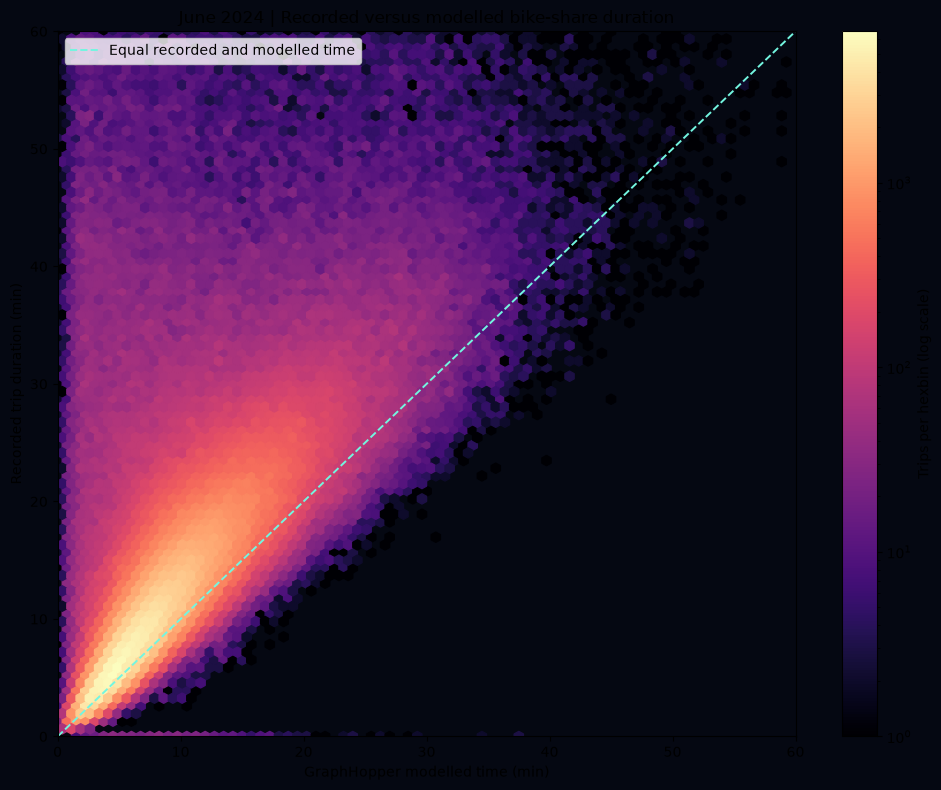

Trip records visible in plot: 723,921 of 737,915


In [5]:
plot_data = joined.loc[joined.observed_min.between(0,60) & joined.time_min.between(0,60)]
fig, ax = plt.subplots(figsize=(10,8),facecolor='#050812')
ax.set_facecolor('#050812')
hb = ax.hexbin(plot_data.time_min,plot_data.observed_min,gridsize=80,
               extent=(0,60,0,60),mincnt=1,bins='log',cmap='magma')
ax.plot([0,60],[0,60],ls='--',color='#73f6e0',lw=1.4,label='Equal recorded and modelled time')
ax.set(xlim=(0,60),ylim=(0,60),xlabel='GraphHopper modelled time (min)',
       ylabel='Recorded trip duration (min)',title='June 2024 | Recorded versus modelled bike-share duration')
ax.legend()
fig.colorbar(hb,ax=ax,label='Trips per hexbin (log scale)')
fig.tight_layout()
fig.savefig(OUT/'01_observed_vs_modelled_hexbin.png',dpi=210,facecolor=fig.get_facecolor())
plt.show();plt.close(fig)
print('Trip records visible in plot:',f'{len(plot_data):,}', 'of',f'{len(joined):,}')


## Figure 2 — Distribution of ΔT: *recorded − modelled*

The plot is clipped at −30 to +60 minutes for readability; the summary table above describes the full distribution. Negative values are retained.

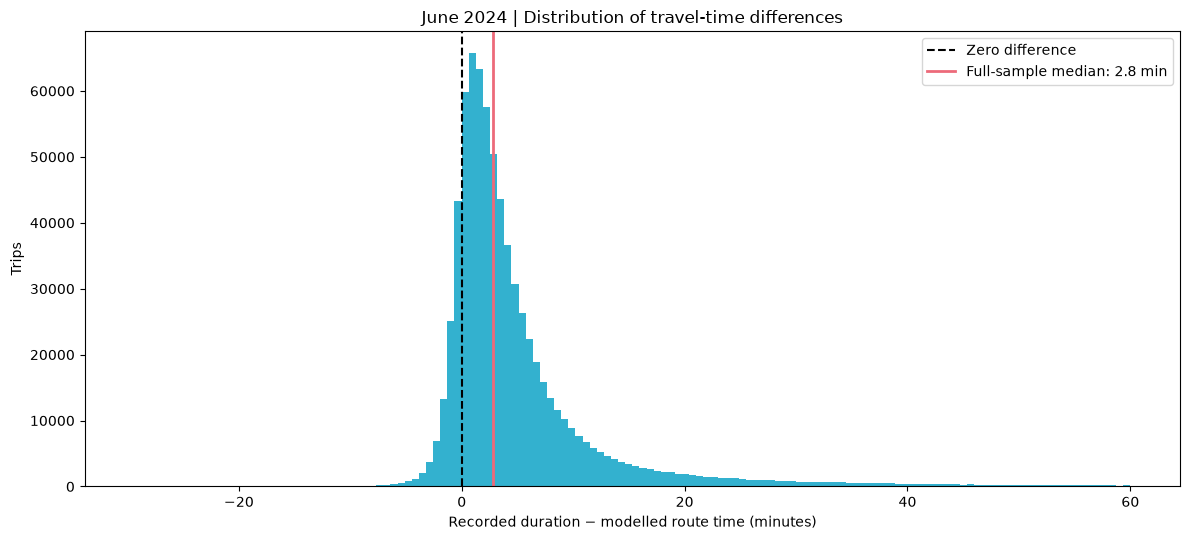

Displayed 728,767/737,915 trips in −30 to 60 min


In [6]:
v = joined['delta_min']; vplot = v.loc[v.between(-30,60)]
fig, ax = plt.subplots(figsize=(12,5.5))
ax.hist(vplot,bins=140,color='#17a7c9',alpha=.88)
ax.axvline(0,color='black',lw=1.5,ls='--',label='Zero difference')
ax.axvline(v.median(),color='#ed6a7a',lw=2,label=f'Full-sample median: {v.median():.1f} min')
ax.set(xlabel='Recorded duration − modelled route time (minutes)',ylabel='Trips',
       title='June 2024 | Distribution of travel-time differences')
ax.legend();fig.tight_layout()
fig.savefig(OUT/'02_time_difference_distribution.png',dpi=210)
plt.show();plt.close(fig)
print(f'Displayed {len(vplot):,}/{len(v):,} trips in −30 to 60 min')


## Figure 3 — Conventional versus electric bikes

**Exploratory only**: the same GraphHopper bike-speed profile was used for both types. Thus, ΔT differences may reflect a **model speed mismatch**, not behaviour. Show both the full sample and a controlled sensitivity subset; do not infer causal effects.

               trips  median_min  mean_min  negative_fraction    q10     q90
bike_type                                                                   
Conventional  603250       3.053     5.619              0.106 -0.056  13.000
Electric      127603       1.550     4.142              0.271 -1.416  11.165


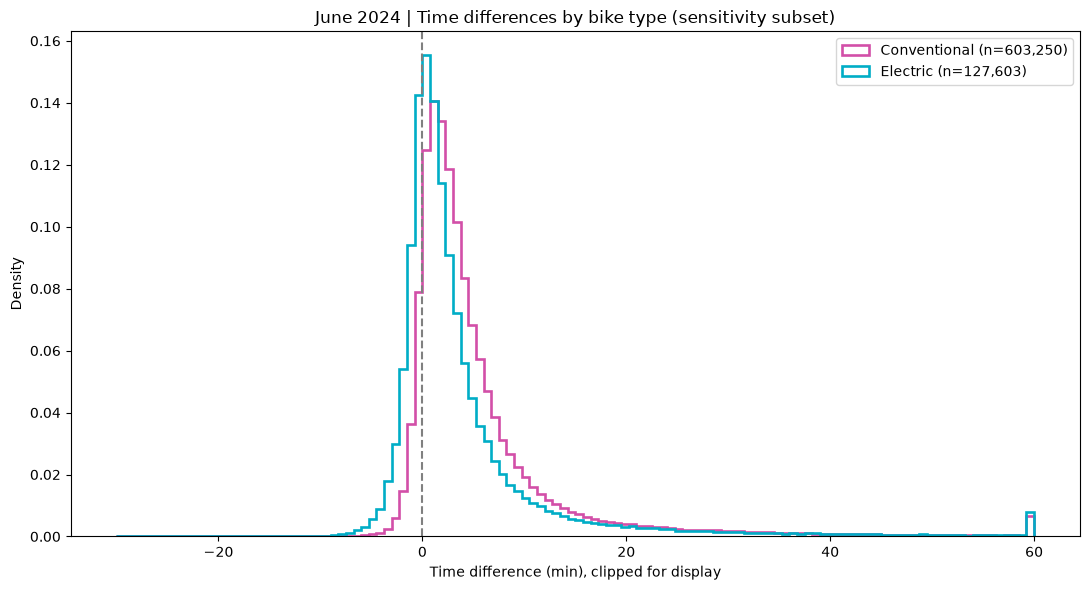

In [7]:
types = ['Conventional','Electric']
subset = sensitivity.loc[sensitivity.bike_type.isin(types)]
summary = subset.groupby('bike_type')['delta_min'].agg(
    trips='size',median_min='median',mean_min='mean',negative_fraction=lambda x:(x<0).mean(),
    q10=lambda x:x.quantile(.10),q90=lambda x:x.quantile(.90))
print(summary.round(3))
fig, ax = plt.subplots(figsize=(11,6))
for kind,color in [('Conventional','#d24fa8'),('Electric','#00adc6')]:
    vals = subset.loc[subset.bike_type.eq(kind),'delta_min'].clip(-30,60)
    ax.hist(vals,bins=np.linspace(-30,60,121),histtype='step',density=True,
            linewidth=1.9,color=color,label=f'{kind} (n={len(vals):,})')
ax.axvline(0,color='gray',ls='--')
ax.set(xlabel='Time difference (min), clipped for display',ylabel='Density',
       title='June 2024 | Time differences by bike type (sensitivity subset)')
ax.legend();fig.tight_layout()
fig.savefig(OUT/'03_time_difference_by_bike_type.png',dpi=210)
plt.show();plt.close(fig)


## Figure 4 — Hour-of-day changes (weekday versus weekend)

Group by **departure hour**. Compare medians, with sample size printed to avoid interpreting sparse strata.

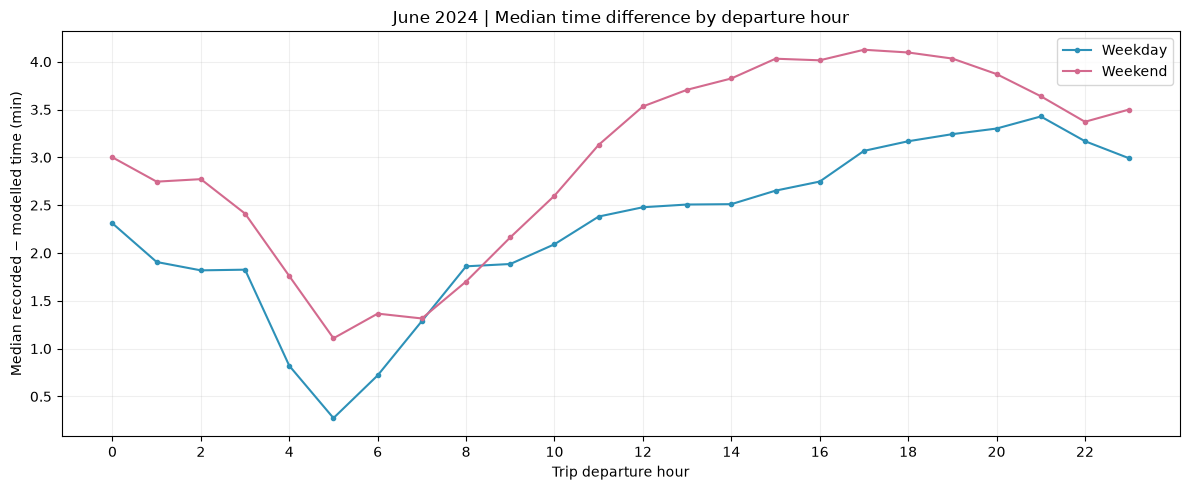

weekend  False  True 
hour                 
0         5531   5261
1         2656   4082
2         1730   3471
3          946   1711
4         1042    899


In [8]:
hourly = (sensitivity.groupby(['weekend','hour'])['delta_min']
          .agg(median_min='median',n='size').reset_index())
fig, ax = plt.subplots(figsize=(12,5))
for weekend,colour,label in [(False,'#2d91b8','Weekday'),(True,'#d36a8e','Weekend')]:
    h = hourly.loc[hourly.weekend.eq(weekend)]
    ax.plot(h.hour,h.median_min,marker='o',ms=3,color=colour,label=label)
ax.set(xlabel='Trip departure hour',ylabel='Median recorded − modelled time (min)',
       title='June 2024 | Median time difference by departure hour')
ax.set_xticks(range(0,24,2));ax.grid(alpha=.2);ax.legend();fig.tight_layout()
fig.savefig(OUT/'04_hourly_median_difference.png',dpi=210)
plt.show();plt.close(fig)
print(hourly.pivot(index='hour',columns='weekend',values='n').fillna(0).astype(int).head())


## 4 — OD-level indicators (repeated journeys between the same stations)

Summarise OD pairs using **trip volume, median time difference, interquartile range, and fraction below the modelled time**. Use a minimum sample size when ranking OD differences. The resulting table is a behavioural baseline, **not an exposure metric**.

In [9]:
od = (joined.groupby(['Start_Station_Id','End_Station_Id'],dropna=False)
      .agg(n_trips=('delta_min','size'),
           median_delta_min=('delta_min','median'),
           mean_delta_min=('delta_min','mean'),
           p25_delta_min=('delta_min',lambda x:x.quantile(.25)),
           p75_delta_min=('delta_min',lambda x:x.quantile(.75)),
           share_negative=('delta_min',lambda x:(x<0).mean()),
           route_distance_m=('distance_m','first'),
           modelled_min=('time_min','first')).reset_index())
od['iqr_delta_min'] = od.p75_delta_min - od.p25_delta_min
od.to_parquet(OUT/'june_2024_od_travel_time_summary.parquet',index=False)
print('Directed OD pairs with trips:',f'{len(od):,}')
print('OD pairs with >= 20 trips:',f'{(od.n_trips>=20).sum():,}')
print('Largest median differences among OD pairs with >=20 trips:')
print(od.loc[od.n_trips.ge(20)].nlargest(15,'median_delta_min')
      [['Start_Station_Id','End_Station_Id','n_trips','median_delta_min','iqr_delta_min']].to_string(index=False))


Directed OD pairs with trips: 163,026
OD pairs with >= 20 trips: 5,346
Largest median differences among OD pairs with >=20 trips:
Start_Station_Id End_Station_Id  n_trips  median_delta_min  iqr_delta_min
            7616           7626       31         53.136300      28.250000
            7626           7616       28         52.294633      51.745833
            7288           7838       28         50.853550      56.579167
            7222           7518       27         48.557267      29.033333
            7220           7225       38         46.849217      68.429167
            7794           7016       20         46.217533     146.187500
            7168           7016       96         44.040550     123.583333
            7175           7018       30         42.518233      53.829167
            7822           7354       72         41.057117      62.841667
            7377           7709       25         40.779467      20.450000
            7314           7427       37         39.4950

## Figure 5 — OD sample size versus median ΔT

An OD with two trips is not equally reliable as an OD with 200. Visualising sample size is a useful precursor to any station or corridor hotspot map.

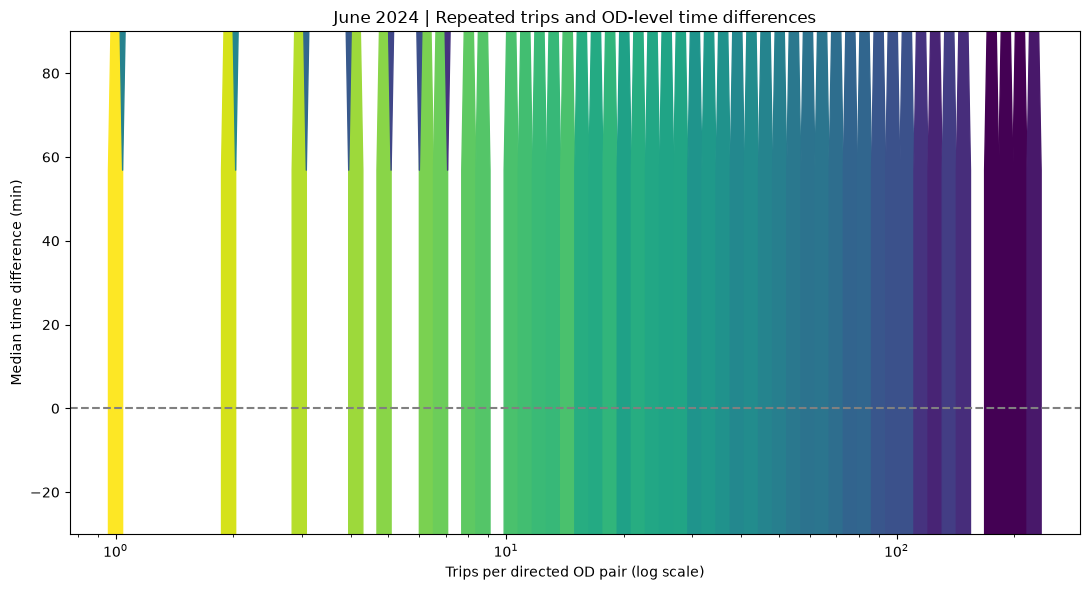

In [10]:
fig,ax=plt.subplots(figsize=(11,6))
x=od.n_trips.to_numpy();y=od.median_delta_min.to_numpy()
ax.hexbin(x,y,xscale='log',gridsize=65,mincnt=1,bins='log',cmap='viridis',extent=None)
ax.axhline(0,color='gray',ls='--')
ax.set(xlabel='Trips per directed OD pair (log scale)',ylabel='Median time difference (min)',
       title='June 2024 | Repeated trips and OD-level time differences',ylim=(-30,90))
fig.tight_layout();fig.savefig(OUT/'05_od_sample_size_vs_median.png',dpi=210)
plt.show();plt.close(fig)


## 5 — Write compact outputs for the next research stage

Only derived metrics are saved to the research project `outputs/` directory (not committed to GitHub). Individual trip-level joined data are *not* exported by default. Use the notebook code for reproducibility.

In [11]:
qa = pd.DataFrame([{
    'raw_trip_count':len(trips),
    'eligible_trip_count':len(base),
    'routed_joined_trips':len(joined),
    'matched_share_raw':len(joined)/len(trips),
    'negative_difference_share':float(joined.delta_min.lt(0).mean()),
    'median_difference_min':float(joined.delta_min.median()),
    'sensitivity_n':len(sensitivity),
    'route_snapshot_note':'OSM downloaded 2026; not historical June 2024',
    'station_note':'Provisional locations; not all June 2024 verified'
}])
qa.to_csv(OUT/'june_2024_baseline_quality_summary.csv',index=False)
print('Saved analysis files under:', OUT)
for p in sorted(OUT.iterdir()): print(' -',p.name)


Saved analysis files under: /scratch/project_2010417/paper3/toronto-bike-exposure/outputs/guo_travel_time_baseline
 - 01_observed_vs_modelled_hexbin.png
 - 02_time_difference_distribution.png
 - 03_time_difference_by_bike_type.png
 - 04_hourly_median_difference.png
 - 05_od_sample_size_vs_median.png
 - june_2024_baseline_quality_summary.csv
 - june_2024_od_travel_time_summary.parquet


## Next steps toward Guo et al. and Paper 3

1. **Validate the baseline** against observed time distributions, plausible bike speeds, known station changes and a bicycle-type-specific speed sensitivity analysis.
2. **Define meaningful excess-time indicators** only after specifying the reference trip definition and whether time is positive/negative; investigate trip-purpose proxies and same-station exclusions.
3. **Spatial and temporal comparisons:** produce robust station/OD maps with minimum sample sizes; compare weekdays, weekends and hours with uncertainty measures.
4. **Then** introduce ambient PM₂.₅ or heat and examine mobility adaptations, controlling for calendar and weather conditions. An ambient concentration-time estimate is **not inhaled dose**.

**Interpretation warning:** recorded minus GraphHopper modelled time is not necessarily time spent on an unnecessary detour, and it cannot establish personal exposure or behaviour during a pollution event on its own.
